In [12]:
import os

# Dataset location
data_path = "kaggle/data"

# Inspect folders
for folder in os.listdir(data_path):
    folder_path = os.path.join(data_path, folder)

    if os.path.isdir(folder_path):
        files = os.listdir(folder_path)

        print(f"\nFolder: {folder}")
        print(f"Total files: {len(files)}")
        print("Sample files:", files[:5])


Folder: Class_0
Total files: 3695
Sample files: ['class_0_00001.jpg', 'class_0_00002.jpg', 'class_0_00003.jpg', 'class_0_00004.jpg', 'class_0_00005.jpg']

Folder: Class_1
Total files: 1843
Sample files: ['class_1_00001.jpg', 'class_1_00002.jpg', 'class_1_00003.jpg', 'class_1_00004.jpg', 'class_1_00005.jpg']

Folder: sample
Total files: 2
Sample files: ['Class_0', 'Class_1']


Class Distribution:
           Class  Image Count  Percentage
0  Non-Oil Spill         3695   66.720838
1      Oil Spill         1843   33.279162

Total Images: 5538


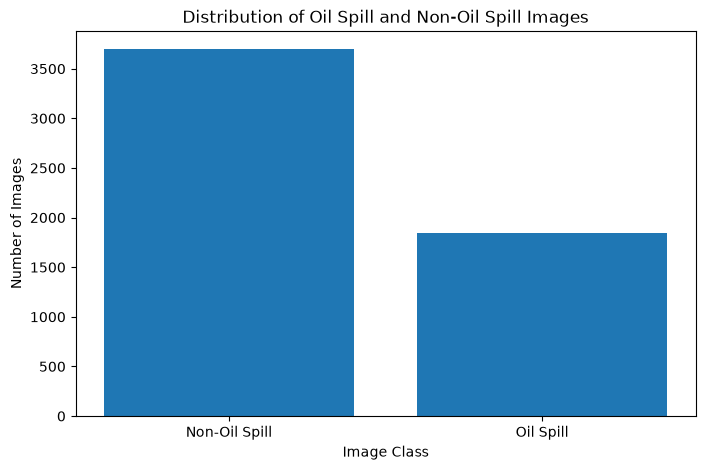

In [13]:
# Class Distribution Analysis

import matplotlib.pyplot as plt
import pandas as pd

# Number of images in each class
class_counts = {
    "Non-Oil Spill": 3695,
    "Oil Spill": 1843
}

# Create a DataFrame
df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Image Count"]
)

# Calculate percentages
total_images = df["Image Count"].sum()

df["Percentage"] = (
    df["Image Count"] / total_images
) * 100

# Display results
print("Class Distribution:")
print(df)

print("\nTotal Images:", total_images)

# Create bar chart
plt.figure(figsize=(8, 5))

plt.bar(
    df["Class"],
    df["Image Count"]
)

plt.title("Distribution of Oil Spill and Non-Oil Spill Images")
plt.xlabel("Image Class")
plt.ylabel("Number of Images")

plt.show()

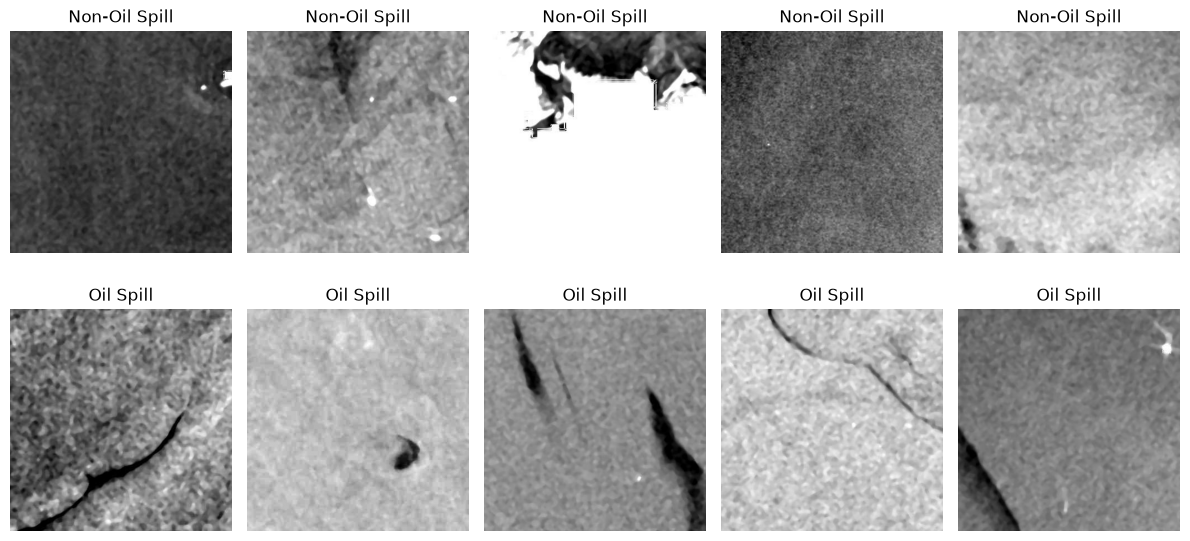

In [14]:
# Image Visualization

import cv2
import os
import matplotlib.pyplot as plt
import random

# Dataset paths
class_0_path = "kaggle/data/Class_0"
class_1_path = "kaggle/data/Class_1"

# Select 5 random images from each class
images_0 = random.sample(os.listdir(class_0_path), 5)
images_1 = random.sample(os.listdir(class_1_path), 5)

# Create image grid
plt.figure(figsize=(12, 6))

# Display Class 0
for i, img_name in enumerate(images_0):
    img = cv2.imread(
        os.path.join(class_0_path, img_name),
        cv2.IMREAD_GRAYSCALE
    )

    plt.subplot(2, 5, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title("Non-Oil Spill")
    plt.axis("off")

# Display Class 1
for i, img_name in enumerate(images_1):
    img = cv2.imread(
        os.path.join(class_1_path, img_name),
        cv2.IMREAD_GRAYSCALE
    )

    plt.subplot(2, 5, i + 6)
    plt.imshow(img, cmap="gray")
    plt.title("Oil Spill")
    plt.axis("off")

plt.tight_layout()
plt.show()

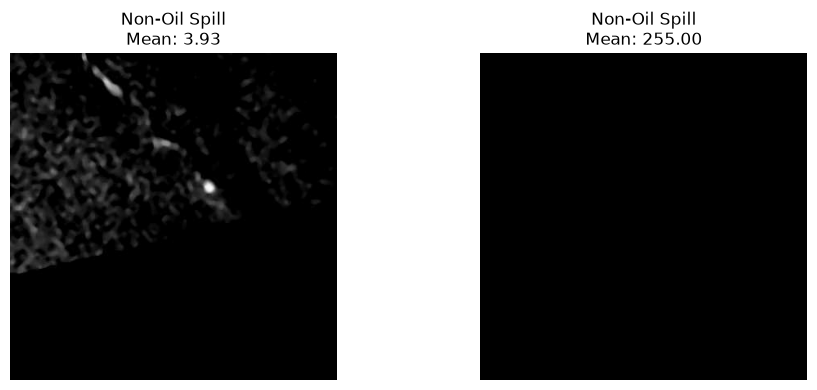

Darkest Image:
Class                 Non-Oil Spill
Filename          class_0_01350.jpg
Mean Intensity             3.931944
Name: 1349, dtype: object

Brightest Image:
Class                 Non-Oil Spill
Filename          class_0_02934.jpg
Mean Intensity                255.0
Name: 2933, dtype: object


In [15]:
import numpy as np
import pandas as pd
import cv2
import os
import matplotlib.pyplot as plt
# Find images with highest and lowest mean intensity

image_data = []

for class_name, folder in [
    ("Non-Oil Spill", class_0_path),
    ("Oil Spill", class_1_path)
]:
    for filename in os.listdir(folder):

        path = os.path.join(folder, filename)

        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

        if img is not None:
            mean_value = np.mean(img)

            image_data.append({
                "Class": class_name,
                "Filename": filename,
                "Path": path,
                "Mean Intensity": mean_value
            })

# Convert results into a DataFrame
intensity_df = pd.DataFrame(image_data)

# Find darkest and brightest images
darkest = intensity_df.loc[intensity_df["Mean Intensity"].idxmin()]
brightest = intensity_df.loc[intensity_df["Mean Intensity"].idxmax()]

# Display both images
plt.figure(figsize=(10, 4))

for i, row in enumerate([darkest, brightest]):
    img = cv2.imread(row["Path"], cv2.IMREAD_GRAYSCALE)

    plt.subplot(1, 2, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title(f'{row["Class"]}\nMean: {row["Mean Intensity"]:.2f}')
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Darkest Image:")
print(darkest[["Class", "Filename", "Mean Intensity"]])

print("\nBrightest Image:")
print(brightest[["Class", "Filename", "Mean Intensity"]])

In [16]:
# Investigate darkest and brightest images

for name, row in [("Darkest", darkest), ("Brightest", brightest)]:

    img = cv2.imread(row["Path"], cv2.IMREAD_GRAYSCALE)

    print(f"\n{name} Image")
    print("Filename:", row["Filename"])
    print("Dimensions:", img.shape)
    print("Minimum pixel:", np.min(img))
    print("Maximum pixel:", np.max(img))
    print("Mean intensity:", np.mean(img))
    print("Standard deviation:", np.std(img))
    print("Unique pixel values:", len(np.unique(img)))


Darkest Image
Filename: class_0_01350.jpg
Dimensions: (400, 400)
Minimum pixel: 0
Maximum pixel: 134
Mean intensity: 3.93194375
Standard deviation: 9.106280777399517
Unique pixel values: 133

Brightest Image
Filename: class_0_02934.jpg
Dimensions: (400, 400)
Minimum pixel: 255
Maximum pixel: 255
Mean intensity: 255.0
Standard deviation: 0.0
Unique pixel values: 1


In [17]:
# Calculate statistics for all images

statistics = []

for class_name, folder in [
    ("Non-Oil Spill", class_0_path),
    ("Oil Spill", class_1_path)
]:
    for filename in os.listdir(folder):

        path = os.path.join(folder, filename)

        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

        if img is not None:
            statistics.append({
                "Filename": filename,
                "Class": class_name,
                "Mean": np.mean(img),
                "Standard Deviation": np.std(img)
            })

# Create DataFrame
stats_df = pd.DataFrame(statistics)

# Display results
print("Image Statistics:")
print(stats_df.head())

print("\nSummary Statistics:")
print(stats_df.groupby("Class")[["Mean", "Standard Deviation"]].describe())

Image Statistics:
            Filename          Class        Mean  Standard Deviation
0  class_0_00001.jpg  Non-Oil Spill  113.674981           31.910500
1  class_0_00002.jpg  Non-Oil Spill  159.215550           41.057468
2  class_0_00003.jpg  Non-Oil Spill  181.227625           16.467608
3  class_0_00004.jpg  Non-Oil Spill  114.153369            2.853721
4  class_0_00005.jpg  Non-Oil Spill   95.933169            6.958901

Summary Statistics:
                 Mean                                                \
                count        mean        std        min         25%   
Class                                                                 
Non-Oil Spill  3695.0  137.712462  49.586733   3.931944  100.150972   
Oil Spill      1843.0  122.123136  39.307227  34.704325   91.482919   

                                                Standard Deviation             \
                      50%         75%       max              count       mean   
Class                              

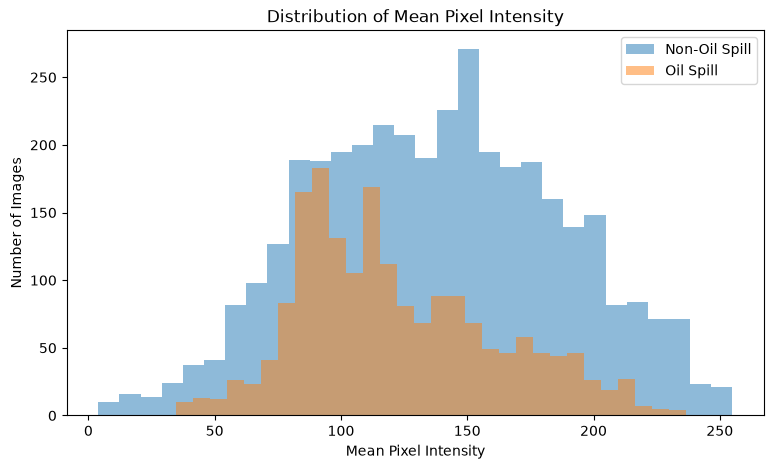

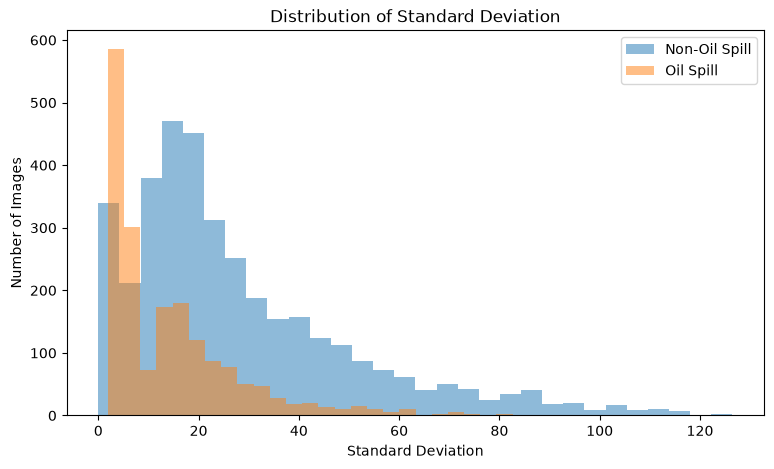

In [18]:
# Distribution of Mean Pixel Intensity

plt.figure(figsize=(9, 5))

for class_name in ["Non-Oil Spill", "Oil Spill"]:
    data = stats_df[stats_df["Class"] == class_name]

    plt.hist(
        data["Mean"],
        bins=30,
        alpha=0.5,
        label=class_name
    )

plt.title("Distribution of Mean Pixel Intensity")
plt.xlabel("Mean Pixel Intensity")
plt.ylabel("Number of Images")
plt.legend()
plt.show()


# Distribution of Standard Deviation

plt.figure(figsize=(9, 5))

for class_name in ["Non-Oil Spill", "Oil Spill"]:
    data = stats_df[stats_df["Class"] == class_name]

    plt.hist(
        data["Standard Deviation"],
        bins=30,
        alpha=0.5,
        label=class_name
    )

plt.title("Distribution of Standard Deviation")
plt.xlabel("Standard Deviation")
plt.ylabel("Number of Images")
plt.legend()
plt.show()

<Figure size 800x500 with 0 Axes>

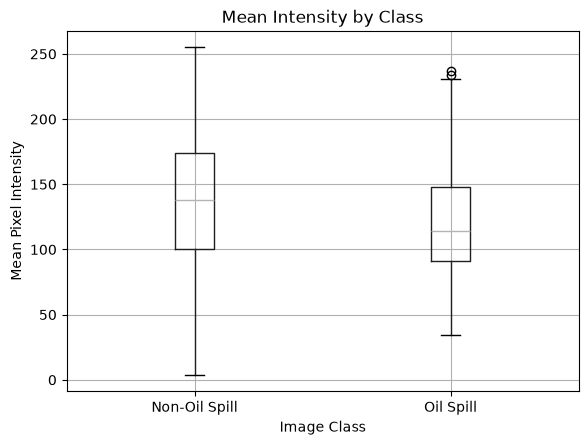

<Figure size 800x500 with 0 Axes>

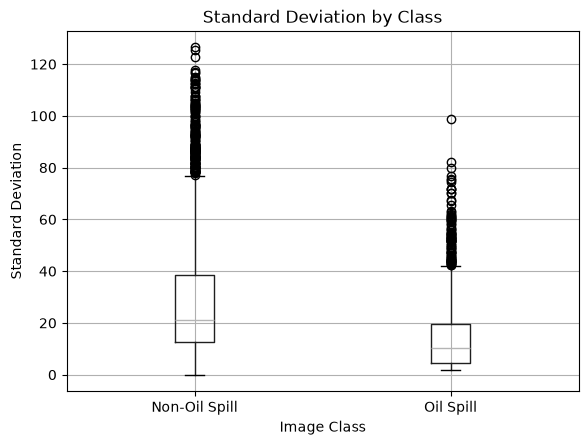

In [19]:
# Box plot of Mean Intensity

plt.figure(figsize=(8, 5))

stats_df.boxplot(
    column="Mean",
    by="Class"
)

plt.title("Mean Intensity by Class")
plt.suptitle("")
plt.xlabel("Image Class")
plt.ylabel("Mean Pixel Intensity")
plt.show()


# Box plot of Standard Deviation

plt.figure(figsize=(8, 5))

stats_df.boxplot(
    column="Standard Deviation",
    by="Class"
)

plt.title("Standard Deviation by Class")
plt.suptitle("")
plt.xlabel("Image Class")
plt.ylabel("Standard Deviation")
plt.show()

In [20]:
# Outlier Detection using IQR Method

metrics = ["Mean", "Standard Deviation"]

for class_name in ["Non-Oil Spill", "Oil Spill"]:

    class_data = stats_df[stats_df["Class"] == class_name]

    print("\nClass:", class_name)

    for metric in metrics:

        Q1 = class_data[metric].quantile(0.25)
        Q3 = class_data[metric].quantile(0.75)

        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        outliers = class_data[
            (class_data[metric] < lower) |
            (class_data[metric] > upper)
        ]

        print(f"\n{metric}")
        print("Lower limit:", round(lower, 2))
        print("Upper limit:", round(upper, 2))
        print("Number of outliers:", len(outliers))

        print("\nExamples:")
        print(outliers.nlargest(3, metric)[
            ["Filename", metric]
        ])


Class: Non-Oil Spill

Mean
Lower limit: -10.72
Upper limit: 284.94
Number of outliers: 0

Examples:
Empty DataFrame
Columns: [Filename, Mean]
Index: []

Standard Deviation
Lower limit: -26.11
Upper limit: 77.04
Number of outliers: 182

Examples:
               Filename  Standard Deviation
1990  class_0_01991.jpg          126.467992
2430  class_0_02431.jpg          125.347355
2336  class_0_02337.jpg          122.852555

Class: Oil Spill

Mean
Lower limit: 7.0
Upper limit: 232.29
Number of outliers: 2

Examples:
               Filename        Mean
4984  class_1_01290.jpg  236.543900
4701  class_1_01007.jpg  234.103306

Standard Deviation
Lower limit: -17.88
Upper limit: 42.12
Number of outliers: 91

Examples:
               Filename  Standard Deviation
4852  class_1_01158.jpg           98.788942
4101  class_1_00407.jpg           82.013032
3856  class_1_00162.jpg           79.997506


In [21]:
# Compact outlier summary

for class_name in ["Non-Oil Spill", "Oil Spill"]:

    data = stats_df[stats_df["Class"] == class_name]

    print("\n", class_name)

    for metric in ["Mean", "Standard Deviation"]:

        Q1 = data[metric].quantile(0.25)
        Q3 = data[metric].quantile(0.75)
        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        count = ((data[metric] < lower) |
                 (data[metric] > upper)).sum()

        print(metric, ":", count, "outliers")


 Non-Oil Spill
Mean : 0 outliers
Standard Deviation : 182 outliers

 Oil Spill
Mean : 2 outliers
Standard Deviation : 91 outliers


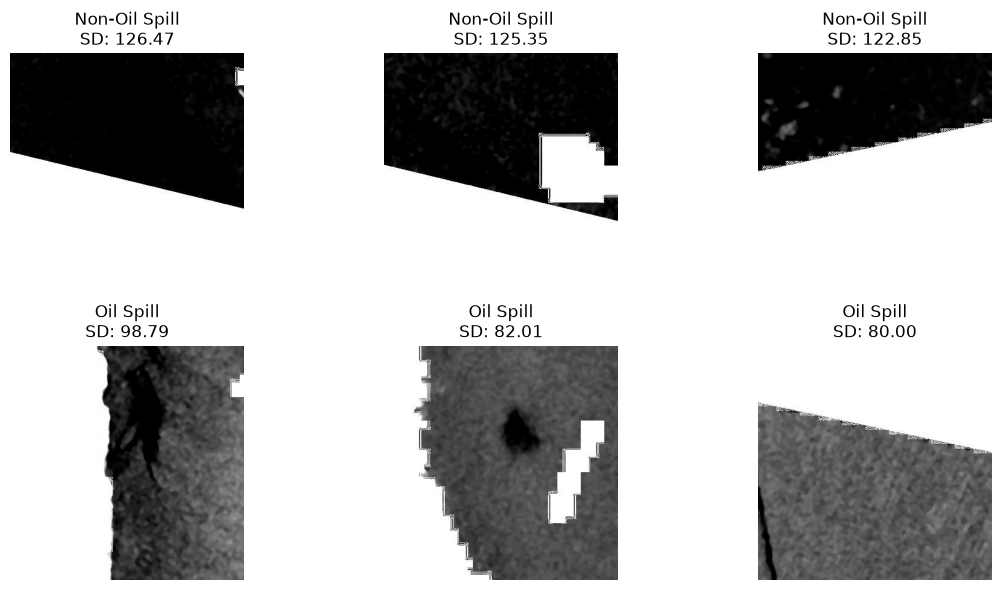

In [22]:
# Display images with highest standard deviation

plt.figure(figsize=(12, 6))

classes = ["Non-Oil Spill", "Oil Spill"]

for i, class_name in enumerate(classes):

    top_images = (
        stats_df[stats_df["Class"] == class_name]
        .nlargest(3, "Standard Deviation")
    )

    for j, (_, row) in enumerate(top_images.iterrows()):

        if class_name == "Non-Oil Spill":
            folder = class_0_path
        else:
            folder = class_1_path

        path = os.path.join(folder, row["Filename"])

        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

        plt.subplot(2, 3, i * 3 + j + 1)
        plt.imshow(img, cmap="gray")
        plt.title(
            f"{class_name}\nSD: {row['Standard Deviation']:.2f}"
        )
        plt.axis("off")

plt.tight_layout()
plt.show()

 1. Project Objective

The goal of this project is to carry out Exploratory Data Analysis on the Sentinel-1 SAR Oil Spill Images data set. We want to learn about the data set layout how many images belong to each class the look of the images, how bright or dark the pixels. If there are any odd images. All of this will be done with Python.

## 2. Tools and Libraries Used

- Python: the language we use.

- NumPy: numerical calculations and pixel intensity statistics.

- Pandas: organising and analysing image statistics.

- Matplotlib: creating graphs and visualizations.

- OpenCV: loading and processing grayscale satellite images.

- Jupyter Notebook: performing and documenting the analysis.

## 3. Dataset Overview

The data set has two kinds of images:

- Class 0: Images that do not show an oil spill.

- Class 1: Images that show an oil spill.

The images are grayscale JPEG files with dimensions of 400 × 400 pixels.

The downloaded data set contains 5,538 images while the supplied metadata says 5,630 images. This difference was seen when we looked at the data set.

## 4. Class Distribution Analysis

The downloaded data set has:

- Non-Oil Spill: 3,695 images (66.72%).

- Oil Spill: 1,843 images (33.28%).

The data set is imbalanced because the non-oil-spill class has twice as many images as the oil‑spill class.

This imbalance must be kept in mind when we look at the results because the larger class adds images to the overall analysis.

## 5. Image Visualization

Random grayscale images from both classes were. Compared.

Observations:

- Nonoil-spill images show different ocean textures, including grainy and relatively uniform regions.

- Oil-spill images frequently contain dark streak‑like structures and irregular patches.

- Dark regions are also present in some non‑oil‑spill images.

Therefore looking at the image cannot reliably tell every oil‑spill image.

## 6. Brightest and Darkest Images

The analysis identified the images:

**Darkest image:**

- Filename: class_0_01350.jpg

- Class: Non-Oil Spill

- Mean intensity: 3.93

- Standard deviation: 9.11

**Brightest image:**

- Filename: class_0_02934.jpg

- Class: Non-Oil Spill

- Mean intensity: 255

- Standard deviation: 0

The brightest image has only pixel values of 255 meaning it is completely white. This may be an image or something that happened during preprocessing and it needs more investigation.

## 7. Image Statistics

The average statistics for both classes are:

| Measurement Non-Oil Spill | Oil Spill |

|---|---:|---:|

| Average mean intensity | 137.71 | 122.12 |

| Average standard deviation | 28.09 | 14.46 |

Non‑oil‑spill images generally have average pixel intensity and more pixel variation than oil‑spill images.

These differences alone do not reliably point to oil spills.

## 8. Outlier Detection

The Interquartile Range (IQR) method was used to find outliers.

| Class Mean Outliers | Standard Deviation Outliers |

|---|---:|---:|

| Non‑O‑… | 0 182 |

| Oil … | 2 | 91 |

The investigation showed images with strong contrast, irregular textures, dark regions and large white boundary areas.

These traits may cause the high standard deviation values.

The outliers are not automatically images; they need more investigation.

## 9. Final Findings and

The analysis found differences in class distribution visual look and pixel intensity statistics between oil‑spill and non‑oil‑spill images.

The data set is imbalanced toward the non‑oil‑spill class. Oil‑spill images often have streak‑like patterns while non‑oil‑spill images show varied ocean textures.

Statistical analysis showed that non‑oil‑spill images usually have mean intensity and standard deviation.

Outlier detection also spotted images in both classes.

Overall this EDA gives a picture of the data set and its image traits. However mean intensity, standard deviation and visual look alone cannot reliably point to oil spills.

## 10. Limitations

- The data set has numbers of images in both classes.

- Some images contain pixel values or might be blank.

- The metadata image count is different from the downloaded image count.

- Visual and statistical checks cannot prove oil‑spill presence, with certainty.

- No machine learning classification model was trained during this EDA project.

